# 16: How cheap must muons get, and what would make them that cheap?

Notebooks 09–10 found muon-catalysed d–t fusion (μCF) ~9× from net electricity and, as a neutron source, about equal to spallation today. Both verdicts hinge on the **beam energy spent per muon stopped in the fuel**, E_μ (≈5 GeV today; ~2 GeV in Kelly et al.'s 2021 design). This notebook turns the question around:

1. What E_μ does each goal require: net electricity (gain 1), a power plant (gain 4), and beating spallation as a neutron source?
2. How much does **recovering the beam heat** help? Most of the proton beam's energy ends as heat in the pion-production target, which a thermal cycle can recover.
3. What production efficiency does each target imply? With $E_\mu = 1/(Y\,\varepsilon)$, $Y$ = π⁻ produced per GeV of beam and $\varepsilon$ = capture × decay-to-μ × stopping. How does that compare with the hard floor that every π⁻ costs at least its rest mass (139.6 MeV)?

**Inputs:** the cycle model and efficiencies are from notebook 09 (X = 150 fusions per muon today, 336 with the sticking and cycling levers; η_th 0.4, η_acc 0.4; 22.4 MeV thermal per fusion with a ⁶Li blanket); spallation gives 27.5 n/GeV (notebook 10). **Recalled, unverified:** E_μ ≈ 5 GeV today and ~2 GeV for the Kelly et al. design; heat-recovery fraction f_heat ≈ 0.8 of the beam energy (assumed).

In [1]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,"font.size":10})
BLUE, ORANGE, AQUA, MAGENTA, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#e87ba4","#0b0b0b","#52514e"
E_TH = 22.4e-3            # GeV thermal per d-t fusion with 6Li blanket
SPALL = 27.5              # n/GeV
M_PI = 0.1396             # GeV, pi- rest mass: hard floor on beam energy per pion
def gain(X, Emu, eta_th=0.4, eta_acc=0.4, f_heat=0.0):
    # electricity out / wall-plug electricity in; recovered beam heat adds eta_th * f_heat * Emu
    return eta_th*(X*E_TH + f_heat*Emu)/(Emu/eta_acc)
def Emu_for(G, X, eta_th=0.4, eta_acc=0.4, f_heat=0.0):
    # solve eta_th*eta_acc*(X E_TH + f Emu) = G Emu
    den = G - eta_th*eta_acc*f_heat
    return np.where(den > 0, eta_th*eta_acc*X*E_TH/den, np.inf)
print(f"check vs notebook 09: X=150, 5 GeV -> gain {gain(150, 5.0):.2f} (nb09: 0.11); "
      f"X=336, 2 GeV, eta 0.5/0.6 -> {gain(336, 2.0, 0.5, 0.6):.2f} (nb09: 1.13)")

check vs notebook 09: X=150, 5 GeV -> gain 0.11 (nb09: 0.11); X=336, 2 GeV, eta 0.5/0.6 -> 1.13 (nb09: 1.13)


In [2]:
CASES = [("today's cycle (X=150), η 0.4/0.4", 150, 0.4, 0.4), ("levers (X=336), η 0.4/0.4", 336, 0.4, 0.4),
         ("levers (X=336), η 0.5/0.6", 336, 0.5, 0.6)]
print(f"{'case':36s} {'heat rec.':>9s} {'E_mu for gain 1':>16s} {'gain 4':>8s}   (GeV of beam per stopped muon)")
for name, X, et, ea in CASES:
    for f in [0.0, 0.8]:
        print(f"{name:36s} {f:9.1f} {float(Emu_for(1, X, et, ea, f)):16.2f} {float(Emu_for(4, X, et, ea, f)):8.2f}")
print(f"\nneutron source: beats spallation when X/E_mu > {SPALL} n/GeV -> E_mu < {150/SPALL:.1f} GeV (X=150), < {336/SPALL:.1f} GeV (X=336)")

case                                 heat rec.  E_mu for gain 1   gain 4   (GeV of beam per stopped muon)
today's cycle (X=150), η 0.4/0.4           0.0             0.54     0.13
today's cycle (X=150), η 0.4/0.4           0.8             0.62     0.14
levers (X=336), η 0.4/0.4                  0.0             1.20     0.30
levers (X=336), η 0.4/0.4                  0.8             1.38     0.31
levers (X=336), η 0.5/0.6                  0.0             2.26     0.56
levers (X=336), η 0.5/0.6                  0.8             2.97     0.60

neutron source: beats spallation when X/E_mu > 27.5 n/GeV -> E_mu < 5.5 GeV (X=150), < 12.2 GeV (X=336)


In [3]:
print("electrical gain without / with heat recovery (f_heat = 0.8):")
for name, X, E, et, ea in [("today: X=150, 5 GeV, η .4/.4", 150, 5.0, .4, .4), ("Kelly design: X=150, 2 GeV, η .4/.4", 150, 2.0, .4, .4),
                           ("Kelly + cycle levers: X=336, 2 GeV, η .4/.4", 336, 2.0, .4, .4), ("Kelly + all levers: X=336, 2 GeV, η .5/.6", 336, 2.0, .5, .6)]:
    print(f"   {name:44s} {gain(X, E, et, ea):5.2f} -> {gain(X, E, et, ea, 0.8):5.2f}")

electrical gain without / with heat recovery (f_heat = 0.8):
   today: X=150, 5 GeV, η .4/.4                  0.11 ->  0.24
   Kelly design: X=150, 2 GeV, η .4/.4           0.27 ->  0.40
   Kelly + cycle levers: X=336, 2 GeV, η .4/.4   0.60 ->  0.73
   Kelly + all levers: X=336, 2 GeV, η .5/.6     1.13 ->  1.37


In [4]:
print("required production efficiency Y·ε (stopped muons per GeV of beam) = 1/E_mu, vs the rest-mass floor")
print(f"   rest-mass floor: at most {1/M_PI:.1f} π⁻ per GeV even if all beam energy became π⁻ rest mass")
targets = [("today (recalled)", 5.0), ("Kelly et al. design (recalled)", 2.0), ("beat spallation, X=150", 150/SPALL),
           ("net electricity, X=150, η .4/.4, heat rec.", float(Emu_for(1, 150, f_heat=0.8))),
           ("net electricity, X=336, η .4/.4, heat rec.", float(Emu_for(1, 336, f_heat=0.8))),
           ("gain 4, X=336, η .5/.6, heat rec.", float(Emu_for(4, 336, 0.5, 0.6, 0.8)))]
for name, E in targets:
    print(f"   {name:44s} E_mu = {E:5.2f} GeV -> Y·ε ≥ {1/E:5.2f} /GeV = {100*M_PI/E:5.1f}% of the rest-mass floor")

required production efficiency Y·ε (stopped muons per GeV of beam) = 1/E_mu, vs the rest-mass floor
   rest-mass floor: at most 7.2 π⁻ per GeV even if all beam energy became π⁻ rest mass
   today (recalled)                             E_mu =  5.00 GeV -> Y·ε ≥  0.20 /GeV =   2.8% of the rest-mass floor
   Kelly et al. design (recalled)               E_mu =  2.00 GeV -> Y·ε ≥  0.50 /GeV =   7.0% of the rest-mass floor
   beat spallation, X=150                       E_mu =  5.45 GeV -> Y·ε ≥  0.18 /GeV =   2.6% of the rest-mass floor
   net electricity, X=150, η .4/.4, heat rec.   E_mu =  0.62 GeV -> Y·ε ≥  1.62 /GeV =  22.6% of the rest-mass floor
   net electricity, X=336, η .4/.4, heat rec.   E_mu =  1.38 GeV -> Y·ε ≥  0.72 /GeV =  10.1% of the rest-mass floor
   gain 4, X=336, η .5/.6, heat rec.            E_mu =  0.60 GeV -> Y·ε ≥  1.67 /GeV =  23.2% of the rest-mass floor


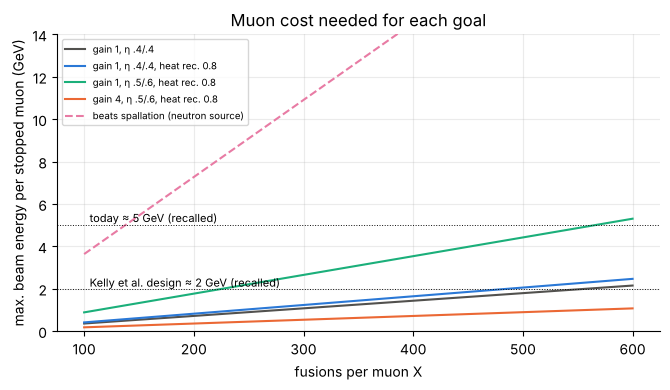

In [5]:
fig, ax = plt.subplots(figsize=(6.8, 4))
X = np.linspace(100, 600, 200)
for (lab, et, ea, f), c in zip([("gain 1, η .4/.4", .4, .4, 0), ("gain 1, η .4/.4, heat rec. 0.8", .4, .4, .8),
                                ("gain 1, η .5/.6, heat rec. 0.8", .5, .6, .8), ("gain 4, η .5/.6, heat rec. 0.8", .5, .6, .8)],
                               [MUTED, BLUE, AQUA, ORANGE]):
    G = 4 if lab.startswith("gain 4") else 1
    ax.plot(X, Emu_for(G, X, et, ea, f), color=c, label=lab)
ax.plot(X, X/SPALL, color=MAGENTA, ls="--", label="beats spallation (neutron source)")
ax.axhline(5, color=INK, lw=.7, ls=":"); ax.text(105, 5.15, "today ≈ 5 GeV (recalled)", fontsize=8)
ax.axhline(2, color=INK, lw=.7, ls=":"); ax.text(105, 2.1, "Kelly et al. design ≈ 2 GeV (recalled)", fontsize=8)
ax.scatter([150, 336], [0, 0], s=0)
ax.set_xlabel("fusions per muon X"); ax.set_ylabel("max. beam energy per stopped muon (GeV)"); ax.set_ylim(0, 14)
ax.legend(fontsize=7, loc="upper left"); ax.set_title("Muon cost needed for each goal")
plt.tight_layout(); plt.savefig("../figures/16_muon_cost_targets.png", dpi=160); plt.show()

## Interpretation

Numbers from the printed results above. Inputs marked "recalled" (5 GeV today, ~2 GeV design, f_heat = 0.8) need primary-source checks.

1. **Net electricity with today's fusion cycle (X = 150) needs muons at 0.54–0.62 GeV each**, 8–9× cheaper than today. That would take a production efficiency of 1.6 stopped muons per GeV, 23% of the absolute rest-mass ceiling. Cheaper muons alone are not a realistic route.
2. **The cycle levers move the target more than the production chain can.** With X = 336 (halved sticking, 3× cycling) and better conversion (η 0.5/0.6), the break-even muon cost rises to 2.3 GeV, or 3.0 GeV with heat recovery. That is above the recalled ~2 GeV of the Kelly et al. design. That combination gives gain 1.13 without and **1.37 with heat recovery**, the first configuration in this project with net electricity, on paper.
3. **Heat recovery is a cheap, missing lever.** Recovering 80% of the beam energy as heat raises the gain by 0.13–0.24 in absolute terms; today's 0.11 becomes 0.24. It costs no new physics, only a hot target. Its value grows as the conversion efficiencies improve.
4. **As a neutron source, μCF already ties spallation** (break-even at 5.45 GeV per muon vs ~5 today). With the cycle levers it wins at any muon cost below 12.2 GeV (by ~2.4× at today's ~5 GeV). For the waste-burning role (notebook 12), **the sticking and cycling measurements (MuFusE) matter more than muon cost.**
5. **A power plant (gain 4) remains out of reach.** Even with every lever, it needs 0.6 GeV per muon, 23% of the rest-mass ceiling.

**Bottom line:** the path where muons win is (i) MuFusE confirming lower sticking and faster cycling at high density, plus (ii) a ~2 GeV-per-muon source with (iii) beam-heat recovery and good conversion. That reaches net electricity (gain ~1.4) but not a commercial plant. The same cycle improvements alone make μCF the better driver for subcritical waste burners.